In [11]:
MODEL_NAME = "Qwen/Qwen1.5-MoE-A2.7B-Chat"
DATASET_NAMES = "openai/gsm8k", "main"

TRAIN_SIZE = 2000
TEST_SIZE = 2000

FUSION_METHODS = {}

# Imports

In [12]:
import torch
import torch.nn as nn
import torch.functional as F
import copy
from matplotlib import pyplot as plt
from tqdm import tqdm
import seaborn as sns
import transformers
import datasets
import time
from collections import defaultdict



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

![ZipIt](img/ZipIt.png)

# Classes

In [ ]:
def unite_matrix(mat1: torch.Tensor, mat2: torch.Tensor) -> torch.Tensor:
    """Unite matrix A and B in block format:
        A 0
        0 B"""
    add1 = torch.zeros((mat1.shape[0], mat2.shape[1]), device=device)
    add2 = torch.zeros((mat2.shape[0], mat1.shape[1]), device=device)
    mat1 = torch.cat([mat1, add1], dim = 1)
    mat2 = torch.cat([add2, mat2], dim = 1)
    return torch.cat([mat1, mat2], dim=0)

def build_matches(corr_matrix):
    """Get a matrix of correlations and build matching with most sum of correlations (greedy)"""
    matches = []
    n = corr_matrix.shape[0]
    used = torch.zeros(n, dtype=torch.bool)
    
    sim_matrix = corr_matrix.clone()
    
    sim_matrix.fill_diagonal_(-float('inf'))
    
    for _ in range(n // 2):
        _, max_idx = torch.max(sim_matrix.view(-1), 0)
        i = max_idx.item() // n
        j = max_idx.item() % n
        
        matches.append((i, j))
        used[i] = True
        used[j] = True
        
        sim_matrix[i, :] = -float('inf')
        sim_matrix[:, i] = -float('inf')
        sim_matrix[j, :] = -float('inf')
        sim_matrix[:, j] = -float('inf')

    del sim_matrix, used
    return matches


class Zipper(nn.Linear):
    """Save all inputs and build M and U matrix based on greedy matching in correlation matrix"""
    def __init__(self, features):
        super().__init__(features, features)
        self.M = None
        self.U = None
        self.activations = []

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if len(x.shape) == 1:
            x = torch.stack([x])
        self.activations.append(x)
        return x

    def build_MU(self):
        """Count M and U matrixes, using saved while training activations"""
        assert len(self.activations) > 0
        activations = torch.cat(self.activations, dim=0)
        corr_matrix = torch.corrcoef(activations.T)
        n = corr_matrix.shape[0]

        matches = build_matches(corr_matrix)
        self.M = torch.zeros(n // 2, n).to(device)
        for idx, (i, j) in enumerate(matches):
            self.M[idx, i] = 0.5
            self.M[idx, j] = 0.5
        self.U = 2 * self.M.T  

        self.activations = []
        del activations
    

In [14]:
class MLP(nn.Module):
    """Base interface for all models"""
    def __init__(self):
        super().__init__()
    
    def forward_unzip(self, x: torch.Tensor):
        """Count forward and return features of model 1 and model 2 concated"""
        raise NotImplementedError()

    def forward(self, x: torch.Tensor):
        raise NotImplementedError()

    def zip_with(self, other: 'MLP'):
        """Make an prezipped model with other"""
        raise NotImplementedError()

    def train_with(self, train_data):
        """Run train data and eval M and U matrix"""
        for example in train_data:
            self.forward(example)
        self.zip1.build_MU()
        self.zip2.build_MU()

    def zip(self):
        """ZipIt operation"""
        raise NotImplementedError()

In [15]:
class SimpleMLP(MLP):
    """MLP with two hidden linear layers"""
    def __init__(self, in_features: int, hid_features: int, out_features: int, bias: bool = False, dtype = None):
        super().__init__()
        self.fc1 = nn.Linear(in_features, hid_features, bias=bias, dtype=dtype, device=device)
        self.zip1 = Zipper(hid_features)
        self.act = nn.ReLU()
        self.fc2 = nn.Linear(hid_features, out_features, bias=bias, dtype=dtype, device=device)
        self.zip2 = Zipper(out_features)
        self.zipped = False
        self.U = None


    def forward_unzip(self, x: torch.Tensor):
        """Count forward and return features of model 1 and model 2 concated"""
        y = self.forward(x)
        if self.U is not None:
            return torch._C._nn.linear(y, self.U)
        else:
            return torch.cat([y, y], dim=-1)

    def forward(self, x: torch.Tensor):
        if self.zipped:
            x = torch.cat([x, x], dim = -1)
            x = self.fc1(x)
            x = self.zip1(x)
            x = self.act(x)
            x = self.fc2(x)
            x = self.zip2(x)
        else:
            x = self.fc1(x)
            x = self.act(x)
            x = self.fc2(x)
        return x

    def zip_with(self, other: 'SimpleMLP'):
        """Make an prezipped model with other"""
        self.fc1.weight = nn.Parameter(unite_matrix(self.fc1.weight, other.fc1.weight))
        self.fc2.weight = nn.Parameter(unite_matrix(self.fc2.weight, other.fc2.weight))
        self.zipped = True

    def zip(self):
        """ZipIt operation"""
        self.U = self.zip2.U

        self.fc1.weight = nn.Parameter(self.zip1.M  @ self.fc1.weight @ torch.cat(2 * [torch.eye(self.fc1.in_features, device=device)]))
        self.fc2.weight = nn.Parameter(self.zip2.M  @ self.fc2.weight @ self.zip1.U)

        self.zipped = False

In [16]:
class AdvancedMLP(MLP):
    """MLP with up, down and proj linear layers"""
    def __init__(self, in_features: int, hid_features: int, out_features: int, bias: bool = False, dtype = None):
        super().__init__()
        self.gate = nn.Linear(in_features, hid_features, bias=bias, dtype=dtype, device=device)
        self.act = nn.SiLU()
        self.up = nn.Linear(in_features, hid_features, bias=bias, dtype=dtype, device=device)
        self.zip1 = Zipper(hid_features)
        self.down = nn.Linear(hid_features, out_features, bias=bias, dtype=dtype, device=device)
        self.zip2 = Zipper(out_features)
        self.zipped = False
        self.U = None


    def forward_unzip(self, x: torch.Tensor):
        """Count forward and return features of model 1 and model 2 concated"""
        y = self.forward(x)
        if self.U is not None:
            return torch._C._nn.linear(y, self.U)
        else:
            return torch.cat([y, y], dim=-1)

    def forward(self, x: torch.Tensor):
        if self.zipped:
            x = torch.cat([x, x], dim = -1)
            gate = self.act(self.gate(x))
            up = self.up(x)
            x = torch.mul(gate, up)
            x = self.zip1(x)
            x = self.down(x)
            x = self.zip2(x)
        else:
            x = self.down(self.act(self.gate(x)) * self.up(x))
        return x

    def zip_with(self, other: 'MLP'):
        """Make an prezipped model with other"""
        self.gate.weight = nn.Parameter(unite_matrix(self.gate.weight, other.gate.weight))
        self.up.weight = nn.Parameter(unite_matrix(self.up.weight, other.up.weight))
        self.down.weight = nn.Parameter(unite_matrix(self.down.weight, other.down.weight))
        self.zipped = True

    def zip(self):
        """ZipIt operation"""
        self.U = self.zip2.U

        self.gate.weight = nn.Parameter(self.zip1.M  @ self.gate.weight @ torch.cat(2 * [torch.eye(self.gate.in_features, device=device)]))
        self.up.weight = nn.Parameter(self.zip1.M  @ self.up.weight @ torch.cat(2 * [torch.eye(self.up.in_features, device=device)]))
        self.down.weight = nn.Parameter(self.zip2.M  @ self.down.weight @ self.zip1.U)

        self.zipped = False

In [ ]:
class Logger(nn.Module):
    """Simple class for saving passing values"""
    def __init__(self, model: nn.Module):
        super().__init__()
        self.model = model
        self.xs: list[torch.Tensor]|None = None

    def forward(self, x: torch.Tensor):
        if self.xs is not None:
            self.xs.append(x)
        return self.model(x)

# Utils

In [18]:
def count_mse(f, x, y):
    """Count MSE if f(x) and y"""
    return torch.mean((f(x) - y) ** 2)

def eval_merger(model1: MLP, model2: MLP, merged_model: MLP, data: torch.Tensor) -> torch.Tensor:
    """Count MSE of zipped model with two simple models"""
    with torch.no_grad():
        return count_mse(merged_model.forward_unzip, data, torch.cat([model1.forward(data), model2.forward(data)], dim=-1))


In [19]:
def zipMLP(mlpA: MLP, mlpB: MLP, train_data: torch.Tensor, create_new: bool = True) -> MLP:
    """Take two MLP models, zipit using train data. Return zipped MLP"""
    with torch.no_grad():
        new_mlp = mlpA
        if create_new:
            new_mlp = copy.deepcopy(mlpA)
        new_mlp.zip_with(mlpB)
        new_mlp.train_with(train_data)
        new_mlp.zip()
    return new_mlp

def avgMLP(mlpA: MLP, mlpB: MLP, train_data: torch.Tensor, create_new: bool = True) -> MLP:
    """Take two MLP models. Return same model with parameters averaged"""
    with torch.no_grad():
        new_mlp = mlpA
        if create_new:
            new_mlp = copy.deepcopy(mlpA)
        new_dict = dict()
        dictA = mlpA.state_dict()
        dictB = mlpB.state_dict()
        for key in dictA.keys():
            new_dict[key] = (dictA[key] + dictB[key]) / 2
        new_mlp.load_state_dict(new_dict)
    return new_mlp
    
def proj(*args):
    return args[0]

FUSION_METHODS["ZipIt"] = zipMLP
FUSION_METHODS["Avarage"] = avgMLP
FUSION_METHODS["Projection"] = proj

In [20]:
def find_mlp_mse_err(merger, n: int, hidden: int, out: int, examples: int = 10_000) -> torch.Tensor:
    """For a given merger make two random models, merge them, train and test on random data. Return it's MSE with original models"""
    with torch.no_grad():
        mlp1 = AdvancedMLP(n, hidden, out)
        mlp2 = AdvancedMLP(n, hidden, out)

        x_train = torch.rand((10 * examples, n), device=device)
        x_test = torch.rand((10 * examples, n), device=device)

        mlp_merged = merger(mlp1, mlp2, x_train)

        res = eval_merger(mlp1, mlp2, mlp_merged, x_test)

    del mlp_merged, x_train, x_test, mlp1, mlp2
    torch.cuda.empty_cache()
    return res

In [21]:
def find_mlp_mse_err_repeat(merger, n: int, hidden: int, out: int, repeat: int = 1000) -> torch.Tensor:
    """Repeat previous test [repeat] times. Return a tensor of results"""
    return torch.stack([find_mlp_mse_err(merger, n, hidden, out, examples=1000) for _ in tqdm(range(repeat))], dim=0).detach().cpu()

In [22]:
def turn_in_mlp(mlp: nn.Module) -> MLP:
    """Extract matrixs from loaded mlp layer and create AdvancedMLP with same weights"""
    new_mlp = AdvancedMLP(mlp.gate_proj.in_features, mlp.gate_proj.out_features, mlp.down_proj.out_features)
    new_mlp.gate = mlp.gate_proj
    new_mlp.up = mlp.up_proj
    new_mlp.down = mlp.down_proj
    return new_mlp

In [23]:
def mse_on_test_data(mlp_zipped: MLP, mlp1: MLP, mlp2: MLP, test_data) -> float:
    """Apply default mlps and zipped version and return MSE between this values"""
    real_res = torch.cat([torch.cat([mlp1.forward(example), mlp2.forward(example)], dim=-1) for example in test_data])
    return torch.mean(torch.square(torch.cat([mlp_zipped.forward_unzip(example)for example in test_data]) - real_res)).item()

def timer(mlp: MLP, test_data) -> float:
    """Apply mlp on data and return required time"""
    start_time = time.time()
    for example in test_data:
        mlp.forward_unzip(example)
    end_time = time.time()
    return end_time - start_time

In [24]:
def compare_fusions_error_and_time(model: nn.Module, train_data, test_data, i: int = 0, j: int = 1) -> tuple[dict[str, list[float]], dict[str, list[float]]]:
    """Take two experts from model first layer and count MSE and time for existed fusion methods"""
    torch.cuda.empty_cache()
    mlp = model.layers[0].mlp
    mlp1 = turn_in_mlp(mlp.experts[i])
    mlp2 = turn_in_mlp(mlp.experts[j])
    fusions = {}
    for fusion_name, fusion_methos in FUSION_METHODS.items():
        fusions[fusion_name] = fusion_methos(mlp1, mlp2, train_data)
    torch.cuda.empty_cache()

    means = {
        f"MSE of {fusion_name}:": mse_on_test_data(fusions[fusion_name], mlp1, mlp2, test_data) 
        for fusion_name, _ in FUSION_METHODS.items()
    }

    times = {
        f"Time of {fusion_name}:": timer(fusions[fusion_name], test_data) 
        for fusion_name, _ in FUSION_METHODS.items()
    }

    del mlp1, mlp2
    for fusion in fusions:
        del fusion
    torch.cuda.empty_cache()
    return means, times

# Examples

In [25]:
# Select shapes
in_f = 20
hid_f = 5
out_f = 10

size = 1000

# Initialize two random MLP layers
mlp1 = AdvancedMLP(in_f, hid_f, out_f)
mlp2 = AdvancedMLP(in_f, hid_f, out_f)

# Generate random train and test data
train_data = torch.rand((size, in_f)).to(device)
test_data = torch.rand((size, in_f)).to(device)

# Apply fusion method
zipit = zipMLP(mlp1, mlp2, train_data)

# Count MSE
print("MSE:", count_mse(zipit.forward_unzip, test_data, torch.cat([mlp1(test_data), mlp2(test_data)], dim=-1)))

MSE: tensor(0.0006, device='cuda:0', grad_fn=<MeanBackward0>)


100%|██████████| 100/100 [00:00<00:00, 1154.42it/s]


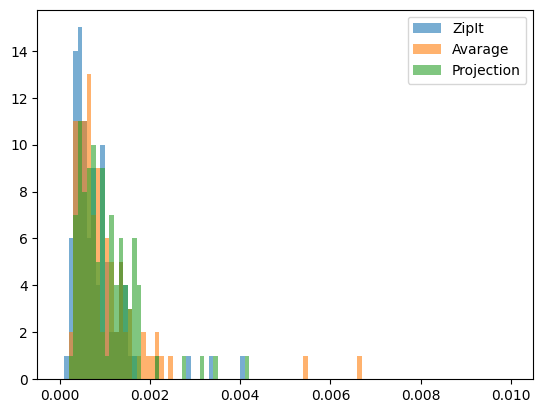

In [ ]:
# 
for fusion_method in FUSION_METHODS.values():
    mse_values = find_mlp_mse_err_repeat(fusion_method, in_f, hid_f, out_f, repeat = 100)
    plt.hist(mse_values, bins=100, range=(0, 0.01), alpha = 0.6)
plt.legend(FUSION_METHODS.keys())

In [ ]:
model = transformers.AutoModel.from_pretrained(MODEL_NAME).to(device)
tokenizer = transformers.AutoTokenizer.from_pretrained(MODEL_NAME)

# Remove extra layers
for i in range(1, len(model.layers)):
    del model.layers[1]

torch.cuda.empty_cache()

W1128 19:39:55.239000 17556 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Loading checkpoint shards:   0%|          | 0/8 [00:00<?, ?it/s]

In [ ]:
train_data = datasets.load_dataset(*DATASET_NAMES, split="train")['question'][:TRAIN_SIZE]
test_data = datasets.load_dataset(*DATASET_NAMES, split="test")['question'][:TEST_SIZE]

In [ ]:
# Use Logger to save inputs in mlp on train and test dataset
logger = Logger(model.layers[0].mlp.shared_expert)
model.layers[0].mlp.shared_expert = logger

logger.xs = []
for example in tqdm(train_data):
    model.forward(tokenizer(example, return_tensors="pt")["input_ids"].to(device))
input_train = logger.xs
logger.xs = None

logger.xs = []
for example in tqdm(test_data):
    model.forward(tokenizer(example, return_tensors="pt")["input_ids"].to(device))
input_test = logger.xs
logger.xs = None

100%|██████████| 1319/1319 [00:25<00:00, 51.28it/s]


In [21]:
len(input_train), len(input_test)

(2000, 1319)

In [ ]:
# Use fusion methods for MLP of model (by default - 0 and 1 experts)
compare_fusions_error_and_time(model, input_train, input_test)

({'MSE of ZipIt:': 0.00097784458193928,
  'MSE of Avarage:': 0.0010676495730876923,
  'MSE of Projection:': 0.001227012136951089},
 {'Time of ZipIt:': 0.15517401695251465,
  'Time of Avarage:': 0.18360590934753418,
  'Time of Projection:': 0.13888835906982422})

In [23]:
all_means = defaultdict(list)
all_times = defaultdict(list)

k = 2
# Use fusion methods for some pairs of experts
for i in tqdm(range(0, len(model.layers[0].mlp.experts), 1)):
    for j in range(i+1, min(i+k+1, len(model.layers[0].mlp.experts) - 1)):
        means, times = compare_fusions_error_and_time(model, input_train, input_test, i, j)
        for key in means.keys():
            all_means[key].append(means[key])
        for key in times.keys():
            all_times[key].append(times[key])


100%|██████████| 60/60 [09:09<00:00,  9.16s/it]


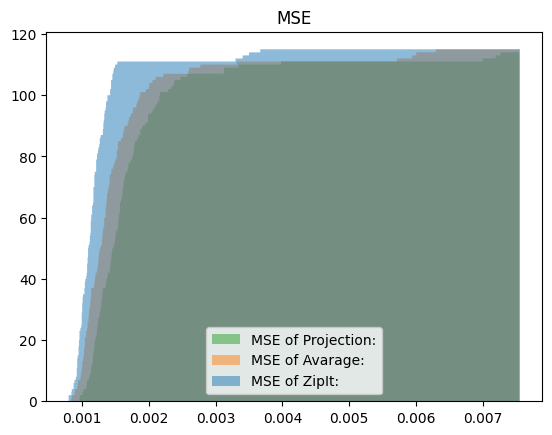

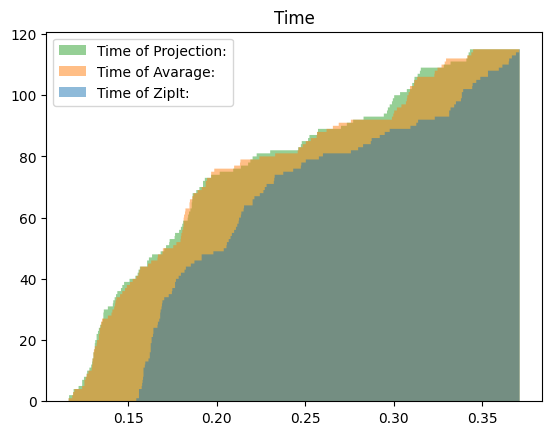

In [49]:
keys = all_means.keys()

plt.hist([all_means[key] for key in keys], bins=1000, histtype="stepfilled", cumulative=True, alpha=0.5, label=keys)
plt.legend()
plt.title("MSE")
plt.show()
keys = all_times.keys()
plt.hist([all_times[key] for key in keys], bins=1000, histtype="stepfilled", cumulative=True, alpha=0.5, label=keys)
plt.legend()
plt.title("Time")
pass

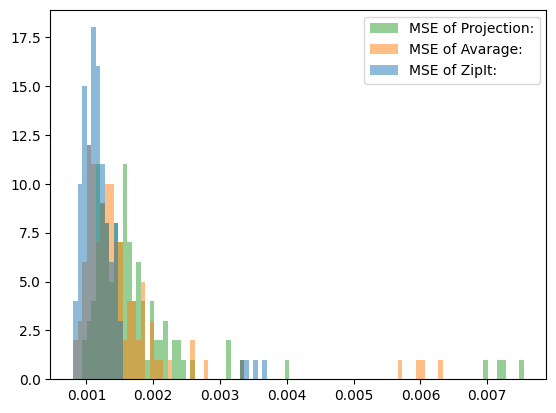

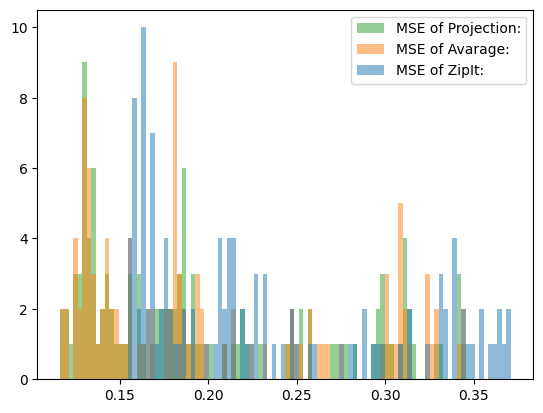

In [50]:
plt.hist(all_means.values(), bins=100, histtype="stepfilled", alpha=0.5, label=all_means.keys())
plt.legend()
plt.show()
plt.hist(all_times.values(), bins=100, histtype="stepfilled", alpha=0.5, label=all_means.keys())
plt.legend()
plt.show()
pass

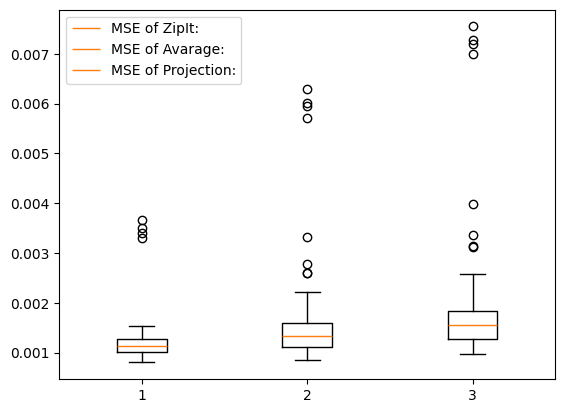

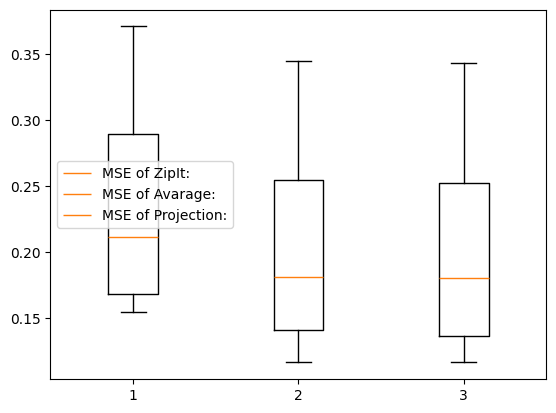

In [51]:
plt.boxplot(all_means.values(), label=all_means.keys())
plt.legend()
plt.show()
plt.boxplot(all_times.values(), label=all_means.keys())
plt.legend()
plt.show()
pass